In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path(r'c:\Users\bhowm\Downloads\Yelp-JSON')
data = pd.read_pickle(ROOT / 'data/02_processed/restaurant_features.pkl')
dev = data.loc[data.split.eq('development')].copy()   # holdout stays untouched
print(data.shape, dev.shape)

(52268, 25) (41802, 25)


In [2]:
numeric = ['latitude', 'longitude', 'category_count', 'listed_days', 'weekly_listed_hours']
categorical = ['state', 'city_state', 'price_range', 'takeout', 'delivery',
               'outdoor_seating', 'reservations', 'alcohol', 'wifi', 'noise_level']

X = dev[numeric + categorical].copy()
y = dev['stars']
# Missing means unknown, not No
for c in categorical:
    X[c] = X[c].astype(object).where(X[c].notna(), 'Unknown')

pre = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)),
                      ('scale', StandardScaler())]), numeric),
    ('cat', OneHotEncoder(drop='first', min_frequency=100,        # rare cities/levels -> "infrequent"
                          handle_unknown='infrequent_if_exist', sparse_output=False), categorical),
])
model = Pipeline([('pre', pre), ('lr', LinearRegression())])
baseline = DummyRegressor(strategy='mean')

In [3]:
cv = KFold(n_splits=5, shuffle=True, random_state=6021)
scoring = {'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error', 'r2': 'r2'}

rows = []
for name, est in [('Mean baseline', baseline), ('Linear regression', model)]:
    res = cross_validate(est, X, y, cv=cv, scoring=scoring)
    rows.append({'model': name, 'RMSE': -res['test_rmse'].mean(), 'MAE': -res['test_mae'].mean(),
                 'R2': res['test_r2'].mean(), 'RMSE_sd': res['test_rmse'].std()})
results = pd.DataFrame(rows).set_index('model')
results.round(3)

c:\Users\bhowm\miniconda3\envs\ds6001\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
c:\Users\bhowm\miniconda3\envs\ds6001\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
c:\Users\bhowm\miniconda3\envs\ds6001\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
c:\Users\bhowm\miniconda3\envs\ds6001\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown cat

,RMSE,MAE,R2,RMSE_sd
model,,,,
Mean baseline,0.832,0.654,-0.000,0.006
Linear regression,0.728,0.580,0.233,0.005


c:\Users\bhowm\miniconda3\envs\ds6001\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
c:\Users\bhowm\miniconda3\envs\ds6001\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
c:\Users\bhowm\miniconda3\envs\ds6001\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
c:\Users\bhowm\miniconda3\envs\ds6001\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown cat

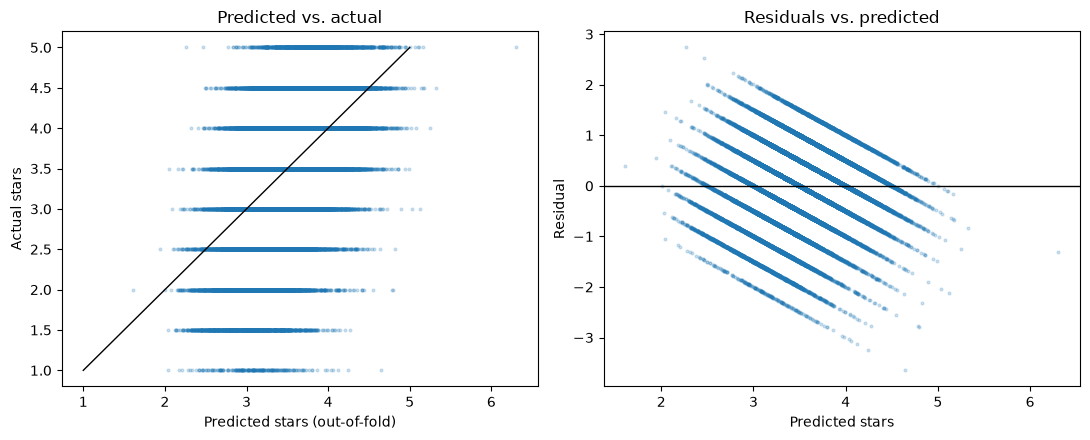

cat__state_LA                   -1.801
cat__state_FL                   -1.795
cat__state_AZ                   -1.774
cat__state_CA                   -1.534
cat__state_NV                   -1.406
cat__state_infrequent_sklearn   -1.385
cat__state_TN                   -1.326
cat__state_MO                   -1.126
cat__state_IL                   -1.101
cat__state_IN                   -0.997
dtype: float64
cat__outdoor_seating_Unknown       0.117
cat__price_range_2                 0.124
cat__city_state_Fishers, IN        0.138
cat__outdoor_seating_Yes           0.139
cat__city_state_Reno, NV           0.149
cat__city_state_New Orleans, LA    0.156
cat__reservations_Unknown          0.158
cat__takeout_Unknown               0.161
cat__takeout_Yes                   0.233
cat__price_range_Unknown           0.413
dtype: float64


In [4]:
oof = cross_val_predict(model, X, y, cv=cv)      # out-of-fold predictions
resid = y - oof

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(oof, y, s=4, alpha=.2)
axes[0].plot([1, 5], [1, 5], color='k', lw=1)
axes[0].set(xlabel='Predicted stars (out-of-fold)', ylabel='Actual stars', title='Predicted vs. actual')
axes[1].scatter(oof, resid, s=4, alpha=.2)
axes[1].axhline(0, color='k', lw=1)
axes[1].set(xlabel='Predicted stars', ylabel='Residual', title='Residuals vs. predicted')
plt.tight_layout(); plt.show()

model.fit(X, y)
coefs = pd.Series(model.named_steps['lr'].coef_,
                  index=model.named_steps['pre'].get_feature_names_out()).sort_values()
print(coefs.head(10).round(3)); print(coefs.tail(10).round(3))